<a href="https://colab.research.google.com/github/giaramayo/Gifs/blob/main/actividad_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IADS5 · TP integrador — Ortelana Textil
## Actividad 01 · Framing, EDA y split de datos

**Alumna:** Gisella Aramayo  
**Comisión:** YA-PAA-A  
**Repositorio GitHub:** [URL]  
**Fecha:** [Completar]

**Qué se espera:** definir el problema, explorar filas, tipos, faltantes y distribución del target; reservar 20 % para test y construir la baseline de clasificación y la de regresión.

**Evidencia a entregar:** EDA documentada; partición persistida y reproducible; predicciones de baseline.

## Registro de decisiones compartidas

| Decisión | Valor |
|---|---|
| Ruta del dataset | `ventas_historicas_ortelana_argentina.csv`, en la misma carpeta que el notebook |
| Target principal (clasificación) | `Format_Reporte`: granularidad con la que la sucursal reporta las ventas de una tela en un año (M = mensual, B = bimestral, S = semestral, C = estacional / temporada comercial) |
| Target secundario (regresión) | `Metros_total`: metros lineales vendidos en el año (suma de `Metros1` a `Metros12`). Es el volumen anual, comparable entre formatos |
| Features candidatas | `Sucursal_ID`, `Año`, `Tela_ID` (y `Format_Reporte` como feature solo para la regresión) |
| Features excluidas | `Metros1` a `Metros12` en clasificación (qué columnas tienen dato depende del formato → fuga) y en regresión (son las partes que suman el target → fuga) |
| Split | 80/20, `random_state=42`, estratificado por `Format_Reporte`. Los mismos índices sirven para las dos tareas |
| Índices persistidos en | `split_indices.csv` (columnas `indice`, `conjunto`) |
| Riesgos de fuga / dependencia | Ver sección 2: el formato está fijo por cada par sucursal–tela y se repite los 10 años |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier, DummyRegressor

RANDOM_STATE = 42
archivo = Path('ventas_historicas_ortelana_argentina.csv')
if not archivo.exists():
    try:
        from google.colab import files
        print('Subí ventas_historicas_ortelana_argentina.csv')
        files.upload()
    except ImportError:
        raise FileNotFoundError('Colocá el CSV en la carpeta de este notebook.')
df = pd.read_csv(archivo)
print('Filas y columnas:', df.shape)
display(df.head())

Subí ventas_historicas_ortelana_argentina.csv


Saving ventas_historicas_ortelana_argentina.csv to ventas_historicas_ortelana_argentina.csv
Filas y columnas: (3285, 16)


,Sucursal_ID,Año,Tela_ID,Format_Reporte,Metros1,Metros2,Metros3,Metros4,Metros5,Metros6,Metros7,Metros8,Metros9,Metros10,Metros11,Metros12
0,1,2016,TELA-001,S,5826.63,5919.77,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2016,TELA-002,C,2747.21,2081.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,2016,TELA-003,S,3711.95,3752.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,2016,TELA-004,B,1275.78,1798.45,1923.95,1861.88,1747.80,1233.24,NaN,NaN,NaN,NaN,NaN,NaN
4,1,2016,TELA-005,M,240.05,241.48,321.98,384.31,396.75,355.00,340.77,383.03,401.43,306.25,278.83,235.65


## 1 · Exploración general

Primero revisamos tipos de datos y valores faltantes por columna.

In [2]:
metros = [f'Metros{i}' for i in range(1, 13)]

resumen = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'faltantes': df.isna().sum(),
    '% faltantes': (df.isna().mean() * 100).round(1)
})
display(resumen)
display(df[['Sucursal_ID', 'Año'] + metros[:2]].describe().round(1))

,tipo,faltantes,% faltantes
Sucursal_ID,int64,0,0.0
Año,int64,0,0.0
Tela_ID,object,0,0.0
Format_Reporte,object,0,0.0
Metros1,float64,0,0.0
Metros2,float64,0,0.0
Metros3,float64,1788,54.4
Metros4,float64,1788,54.4
Metros5,float64,1788,54.4
Metros6,float64,1788,54.4


,Sucursal_ID,Año,Metros1,Metros2
count,3285.0,3285.0,3285.0,3285.0
mean,6.4,2020.5,960.7,956.7
std,3.5,2.9,1103.5,1015.8
min,1.0,2016.0,0.5,0.5
25%,3.0,2018.0,195.6,238.3
50%,6.0,2020.0,536.2,655.0
75%,9.0,2023.0,1376.2,1319.1
max,12.0,2025.0,9487.0,9293.6


`Sucursal_ID`, `Año`, `Tela_ID`, `Format_Reporte`, `Metros1` y `Metros2` no tienen faltantes. Las columnas `Metros3` a `Metros12` sí tienen muchos vacíos, pero **no son errores de carga**: según la documentación del dataset, cada formato usa una cantidad distinta de columnas. Lo verificamos más abajo.

Sucursales: 12 | Años: 10 (2016–2025) | Telas: 30
Combinaciones esperadas: 3600 | Filas reales: 3285 | Faltan: 315 (8.8%)
Filas duplicadas (misma sucursal, año y tela): 0


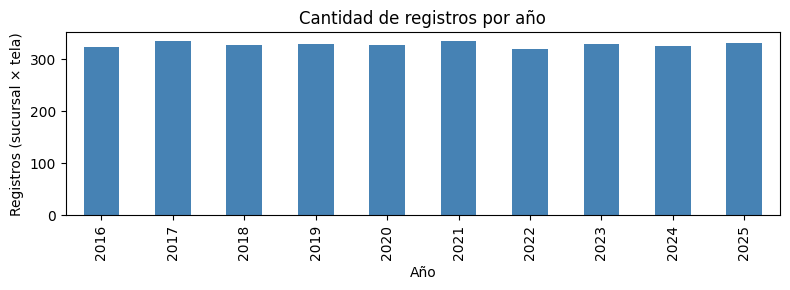

In [3]:
# ¿Están todas las combinaciones sucursal × año × tela?
n_suc, n_anios, n_telas = df['Sucursal_ID'].nunique(), df['Año'].nunique(), df['Tela_ID'].nunique()
esperadas = n_suc * n_anios * n_telas
print(f'Sucursales: {n_suc} | Años: {n_anios} ({df["Año"].min()}–{df["Año"].max()}) | Telas: {n_telas}')
print(f'Combinaciones esperadas: {esperadas} | Filas reales: {len(df)} | Faltan: {esperadas - len(df)} ({(esperadas - len(df)) / esperadas:.1%})')
print('Filas duplicadas (misma sucursal, año y tela):', df.duplicated(['Sucursal_ID', 'Año', 'Tela_ID']).sum())

df.groupby('Año').size().plot(kind='bar', figsize=(8, 3), color='steelblue')
plt.title('Cantidad de registros por año')
plt.xlabel('Año'); plt.ylabel('Registros (sucursal × tela)')
plt.tight_layout(); plt.show()

### Distribución del target principal

,Cantidad,%
Format_Reporte,,
S,928,28.2
C,860,26.2
M,765,23.3
B,732,22.3


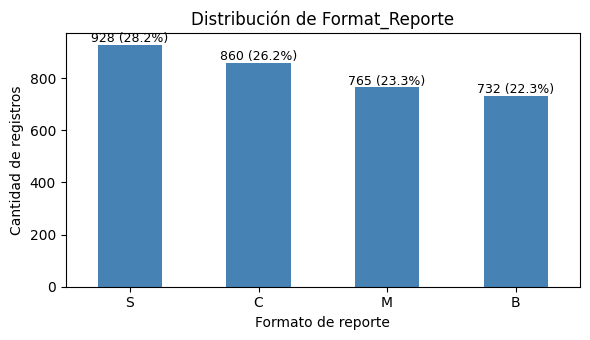

In [4]:
dist = df['Format_Reporte'].value_counts().to_frame('Cantidad')
dist['%'] = (dist['Cantidad'] / len(df) * 100).round(1)
display(dist)

ax = dist['Cantidad'].plot(kind='bar', figsize=(6, 3.5), color='steelblue')
ax.set_title('Distribución de Format_Reporte')
ax.set_xlabel('Formato de reporte'); ax.set_ylabel('Cantidad de registros')
for i, v in enumerate(dist['Cantidad']):
    ax.text(i, v + 10, f"{v} ({dist['%'].iloc[i]}%)", ha='center', fontsize=9)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 2 · Riesgos de fuga y dependencia entre registros

Antes de definir features, revisamos dos cosas: (a) si las columnas `Metros` revelan el formato y (b) si el formato se repite para una misma sucursal y tela.

In [5]:
# (a) Cantidad de columnas Metros con dato según el formato
df['columnas_con_dato'] = df[metros].notna().sum(axis=1)
print('Columnas Metros con dato, según formato:')
display(pd.crosstab(df['Format_Reporte'], df['columnas_con_dato']))

# (b) ¿Cuántos formatos distintos tiene cada par sucursal–tela a lo largo de los 10 años?
formatos_por_par = df.groupby(['Sucursal_ID', 'Tela_ID'])['Format_Reporte'].nunique()
print('Formatos distintos por par sucursal–tela:')
display(formatos_por_par.value_counts().rename_axis('formatos distintos').to_frame('pares'))
df = df.drop(columns='columnas_con_dato')

Columnas Metros con dato, según formato:


columnas_con_dato,2,6,12
Format_Reporte,,,
B,0,732,0
C,860,0,0
M,0,0,765
S,928,0,0


Formatos distintos por par sucursal–tela:


,pares
formatos distintos,
1,360


**Hallazgos:**

- **(a) Fuga por columnas Metros.** La cantidad de columnas con dato identifica el formato de forma exacta: M siempre tiene 12, B tiene 6, y S y C tienen 2. Si el modelo de clasificación usara `Metros3` a `Metros12` (o la cantidad de vacíos), "adivinaría" el formato sin aprender nada útil. Por eso esas columnas quedan **excluidas** como features de clasificación.
- **(b) Dependencia entre registros.** Cada uno de los 360 pares sucursal–tela usa **siempre el mismo formato** en los 10 años. Con un split aleatorio, el mismo par aparece en train y en test, así que el modelo puede memorizar la combinación en vez de generalizar. Lo dejamos documentado: la métrica de test va a medir qué tan bien reconoce pares ya vistos, no sucursales o telas nuevas. Una alternativa más exigente sería separar por grupos (por ejemplo, `GroupShuffleSplit` por par sucursal–tela). Respetamos el split estratificado que pide la consigna y lo tenemos en cuenta al interpretar resultados.

## 3 · Definición del problema

Metros_total (metros lineales por año):


,Metros_total
count,3285.0
mean,3082.5
std,2330.4
min,7.6
25%,1526.6
50%,2526.7
75%,4061.1
max,18780.6


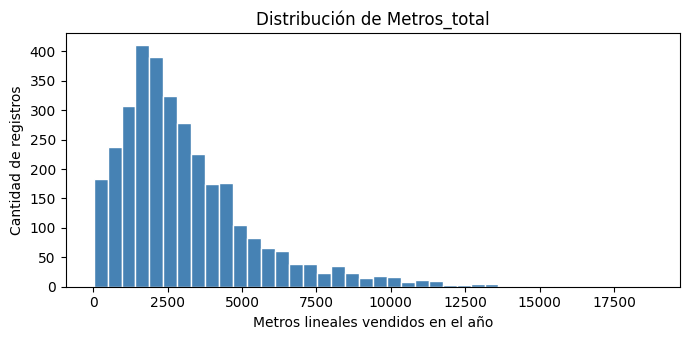

In [6]:
# Target principal: clasificación multiclase
y_clf = df['Format_Reporte']

# Target secundario: regresión del volumen anual
df['Metros_total'] = df[metros].sum(axis=1, min_count=1)
y_reg = df['Metros_total']

features_clf = ['Sucursal_ID', 'Año', 'Tela_ID']
features_reg = ['Sucursal_ID', 'Año', 'Tela_ID', 'Format_Reporte']

print('Metros_total (metros lineales por año):')
display(y_reg.describe().round(1).to_frame())

y_reg.plot(kind='hist', bins=40, figsize=(7, 3.5), color='steelblue', edgecolor='white')
plt.title('Distribución de Metros_total')
plt.xlabel('Metros lineales vendidos en el año'); plt.ylabel('Cantidad de registros')
plt.tight_layout(); plt.show()

- **Clasificación:** `Format_Reporte` es categórico con 4 clases (B, C, M, S), así que es **clasificación multiclase**. Las clases están bastante balanceadas (entre 22 % y 28 %).
- **Regresión:** `Metros_total` es numérico y continuo, así que es **regresión**. Tiene asimetría a la derecha (la media es mayor que la mediana) y algunos valores altos. Sumar las 12 columnas da el volumen anual sin importar el formato, así que los registros son comparables entre sí.

## 4 · Split train / test (se hace una sola vez)

In [7]:
idx_train, idx_test = train_test_split(
    df.index,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_clf
)

# Persistimos los índices para reutilizar exactamente el mismo split en todas las actividades
split = pd.DataFrame({'indice': df.index, 'conjunto': 'train'})
split.loc[split['indice'].isin(idx_test), 'conjunto'] = 'test'
split.to_csv('split_indices.csv', index=False)

X_train_clf, X_test_clf = df.loc[idx_train, features_clf], df.loc[idx_test, features_clf]
y_train_clf, y_test_clf = y_clf.loc[idx_train], y_clf.loc[idx_test]
X_train_reg, X_test_reg = df.loc[idx_train, features_reg], df.loc[idx_test, features_reg]
y_train_reg, y_test_reg = y_reg.loc[idx_train], y_reg.loc[idx_test]

print(f'Train: {len(idx_train)} filas | Test: {len(idx_test)} filas')
proporciones = pd.DataFrame({
    'train %': (y_train_clf.value_counts(normalize=True) * 100).round(1),
    'test %': (y_test_clf.value_counts(normalize=True) * 100).round(1)
})
display(proporciones)

Train: 2628 filas | Test: 657 filas


,train %,test %
Format_Reporte,,
S,28.2,28.3
C,26.2,26.2
M,23.3,23.3
B,22.3,22.2


Las proporciones de cada clase son prácticamente iguales en train y test gracias a `stratify`. Las dos tareas usan **los mismos índices**, así que se evalúan sobre las mismas filas. En las próximas actividades el split se recupera leyendo `split_indices.csv`.

## 5 · Baselines

In [8]:
# Clasificación: predecir siempre la clase más frecuente del train
baseline_clf = DummyClassifier(strategy='most_frequent')
baseline_clf.fit(X_train_clf, y_train_clf)
pred_base_clf = baseline_clf.predict(X_test_clf)

# Regresión: predecir siempre la media del train
baseline_reg = DummyRegressor(strategy='mean')
baseline_reg.fit(X_train_reg, y_train_reg)
pred_base_reg = baseline_reg.predict(X_test_reg)

print('Baseline de clasificación predice siempre:', pred_base_clf[0])
print(f'Baseline de regresión predice siempre: {pred_base_reg[0]:,.1f} metros')

# Guardamos las predicciones para la actividad 2
pd.DataFrame({
    'indice': idx_test,
    'y_real_clf': y_test_clf.values, 'pred_base_clf': pred_base_clf,
    'y_real_reg': y_test_reg.values, 'pred_base_reg': pred_base_reg
}).to_csv('baseline_predicciones_test.csv', index=False)
print('Predicciones guardadas en baseline_predicciones_test.csv')

Baseline de clasificación predice siempre: S
Baseline de regresión predice siempre: 3,093.4 metros
Predicciones guardadas en baseline_predicciones_test.csv


---
### Explicación

**Decisiones técnicas y justificación**

Para la tarea de clasificación se utiliza Format_Reporte como variable objetivo, ya que permite identificar el formato con el que cada sucursal informa las ventas. Para la tarea de regresión, se creo la variable Metros_total, sumando las 12 columnas de metros correspondientes a cada registro, y obtener el total de metros vendidos durante el año, independientemente de cómo se hayan reportado las ventas.

Además, las columnas originales de metros se excluyeron como variables de entrada. En clasificación, estas columnas podrían informar directamente el formato de reporte y generar una fuga de información. En regresión, se excluyeron porque son las variables utilizadas para calcular el objetivo que se busca predecir.

**Interpretación de los resultados**

El dataset tiene 3285 registros que corresponden a 12 sucursales, 10 años y 30 telas. Si estuvieran todas las combinaciones serían 3600, así que faltan 315, que coinciden con los quiebres de stock que menciona en la documentacion. Las cuatro clases están bastante parejas, por eso la baseline que siempre dice "S" acierta poco más de una de cada cuatro. En regresión, la baseline predice siempre 3093 metros, que es el promedio del train.

**Pregunta de análisis:** ¿Qué significa predecir `Format_Reporte` en Ortelana? ¿Qué riesgos de fuga o dependencia entre registros identificás?

Predecir el formato es adivinar cómo va a reportar una sucursal las ventas de una tela por mes, por bimestre, por semestre o por temporada. Encontré dos problemas, primero es que la cantidad de columnas con datos delata el formato las mensuales siempre tienen 12, las bimestrales 6 y el resto 2, así que si el modelo las ve, no aprende nada. El segundo es que cada combinación de sucursal y tela tiene siempre el mismo formato en los 10 años. Con un split al azar, esa misma combinación cae en train y en test, y el modelo puede acertar solo porque la memorizó.

**Limitaciones o mejoras posibles**

La principal limitación de la evaluación es que la división aleatoria de los datos no permite determinar con certeza cómo se comportaría el modelo ante una sucursal o una tela que no haya visto durante el entrenamiento. Para evaluar mejor su capacidad de generalización, se podría separar el conjunto de datos por combinaciones de sucursal y tela, evitando que una misma combinación aparezca tanto en entrenamiento como en prueba. Otra forma de entrenar el modelo con los primeros años y evaluarlo con los últimos, para comprobar su desempeño sobre períodos posteriores. Tambien se identificó una diferencia entre la documentación y los datos. Donde la documentación utiliza la etiqueta E para el formato estacional, mientras que en el dataset aparece la etiqueta C. Ambas representan el mismo formato, aunque sería conveniente verificarlo para evitar errores en la interpretación de las clases.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]